# YOLO-World v2: 


In [1]:
from ultralytics import YOLOWorld

In [2]:
# Load the deployed YOLOv8s-worldv2 model
model = YOLOWorld("models/yolov8s-worldv2.pt")

In [3]:
# Set custom open-vocabulary classes before inference
model.set_classes(["person", "bus", "sign"])

In [4]:
# Run inference
results = model("data/smoke_images/bus.jpg", conf=0.25, iou=0.45, imgsz=640)


image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\bus.jpg: 640x480 4 persons, 1 bus, 11.1ms
Speed: 39.3ms preprocess, 11.1ms inference, 3.4ms postprocess per image at shape (1, 3, 640, 480)


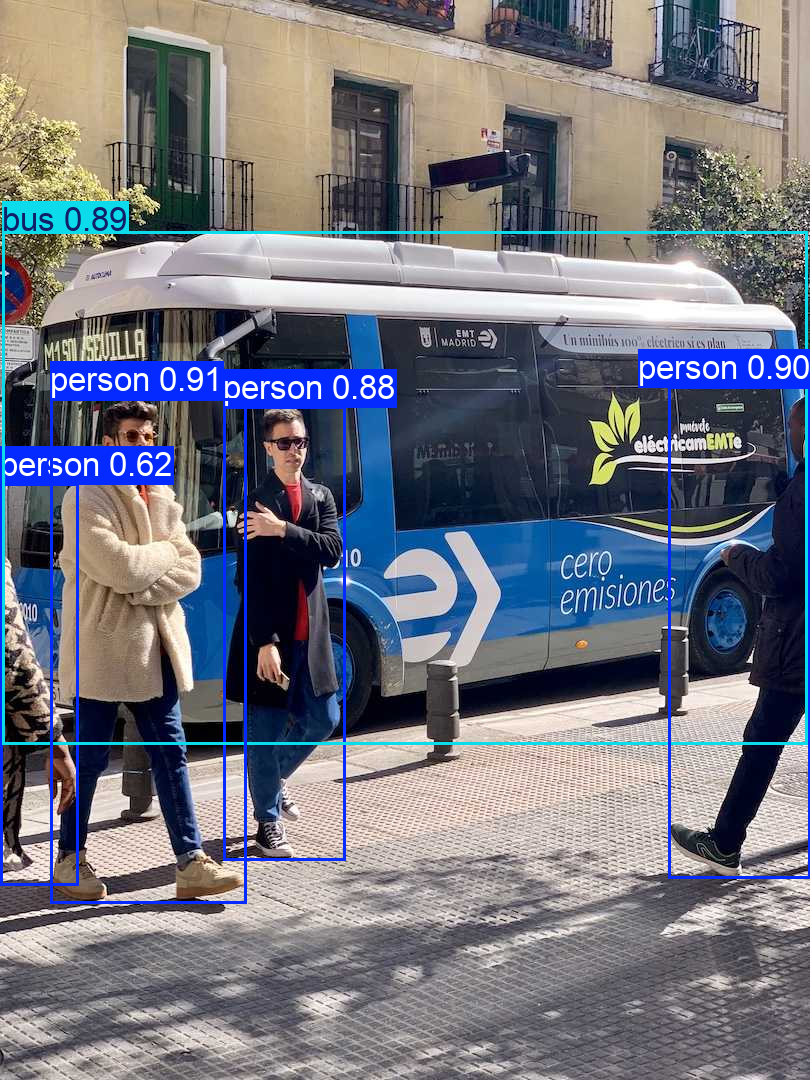

In [5]:
results[0].plot(pil=True)

# Insect Smoke Test


image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img1.jpg: 640x480 3 insects, 12.8ms
Speed: 1.9ms preprocess, 12.8ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img2.jpg: 640x480 (no detections), 9.2ms
Speed: 1.2ms preprocess, 9.2ms inference, 0.4ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img3.jpg: 640x480 2 insects, 11.5ms
Speed: 1.9ms preprocess, 11.5ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img4.jpg: 640x480 1 insect, 14.3ms
Speed: 1.7ms preprocess, 14.3ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\insect_img5.

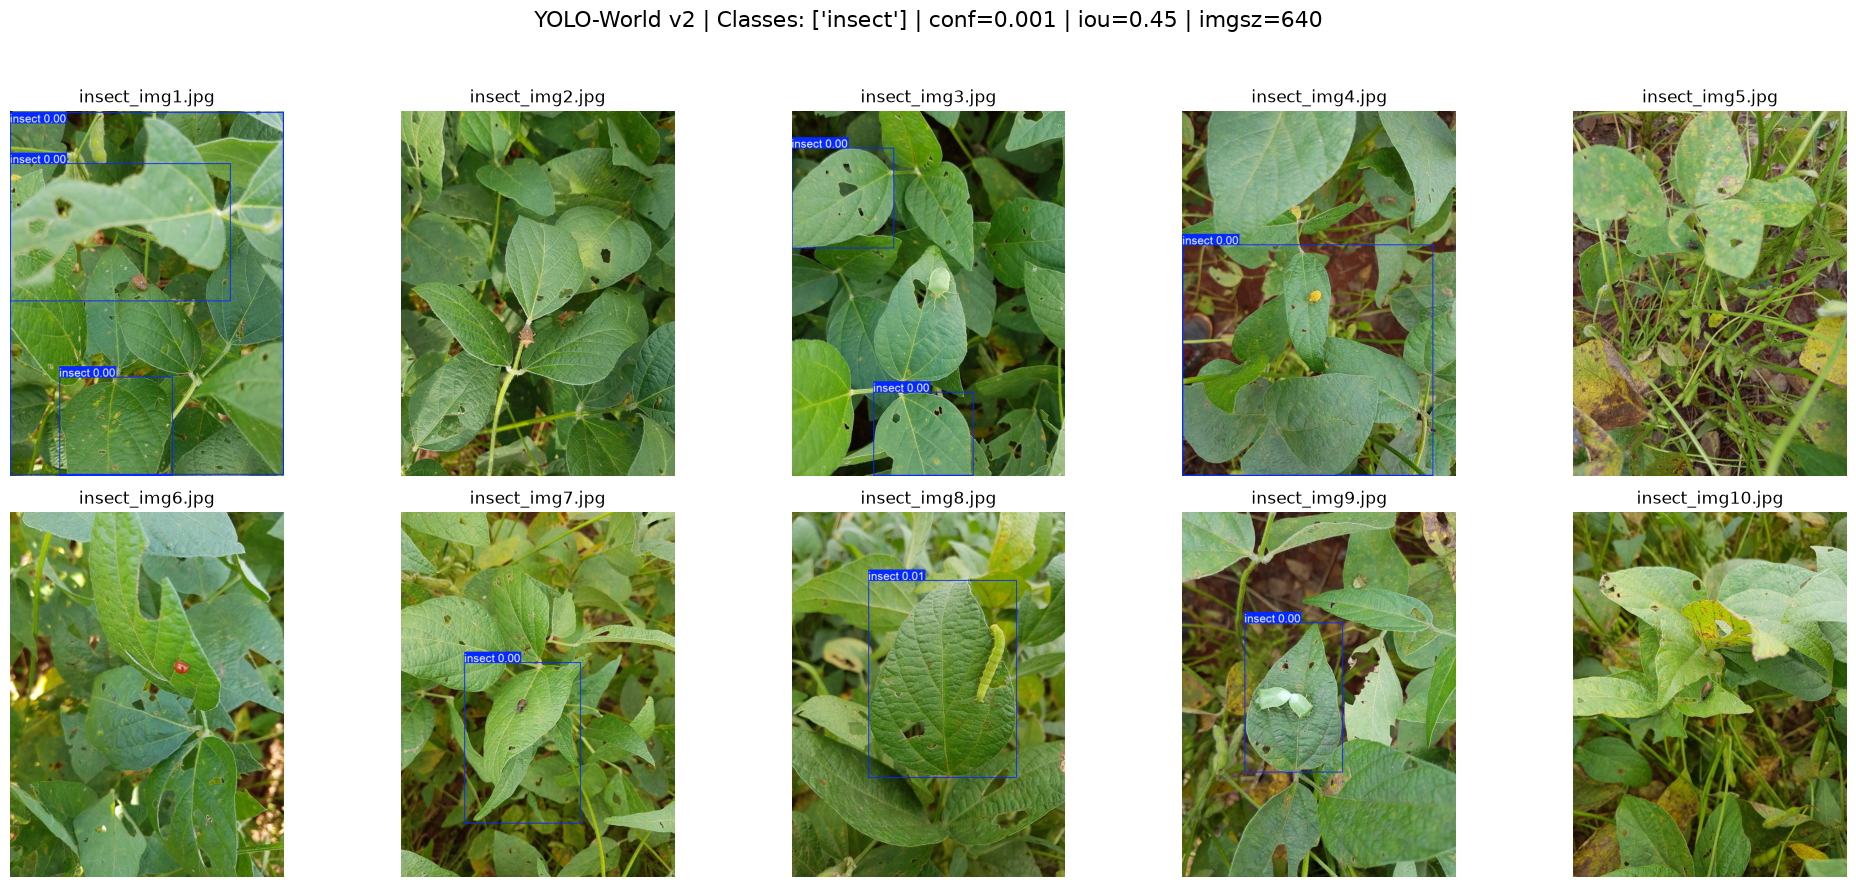

In [6]:
import matplotlib.pyplot as plt

# Load the pretrained model and ask it to look for insects.
model = YOLOWorld("models/yolov8s-worldv2.pt")
classes=["insect"]
model.set_classes(classes)

# conf: Minimum confidence score required to keep a detection.
# Lower = more detections, but potentially more false alarms.
# This score is not a calibrated probability that the box is correct.
confidence_threshold = 0.001

# iou: Box-overlap cutoff used by non-maximum suppression (NMS).
# NMS removes lower-scoring, overlapping boxes to reduce duplicates.
# Lower = more aggressive removal; this can also hide overlapping insects.
# This setting is separate from the IoU threshold used to evaluate AP.
overlap_threshold = 0.45

# imgsz: Target input size in pixels; YOLO resizes/pads the image
# while preserving its aspect ratio, so the input can be rectangular.
# Larger values may help with small insects, but use more time and memory.
image_size = 640

# Make a grid with 2 rows and 5 columns: one panel for each image.
figure, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 9))
figure.suptitle(
    f"YOLO-World v2 | Classes: {classes} | conf={confidence_threshold} | "
    f"iou={overlap_threshold} | imgsz={image_size}",
    fontsize=16,
)

# Keep the exact predictions shown below for the catch-count cell.
smoke_predictions = {}

# axes.flat lets us visit each panel in the grid, one at a time.
for image_number, axis in enumerate(axes.flat, start=1):
    image_path = f"data/smoke_images/insect_img{image_number}.jpg"

    # Run the detector on this image using the settings above.
    results = model(
        image_path,
        conf=confidence_threshold,
        iou=overlap_threshold,
        imgsz=image_size,
    )

    smoke_predictions[image_number] = results[0]

    # We passed one image, so its prediction is the first result: [0].
    # plot() draws the predicted boxes, labels, and confidence scores.
    annotated_image = results[0].plot(pil=True)
    axis.imshow(annotated_image)
    axis.set_title(f"insect_img{image_number}.jpg")
    axis.axis("off")  # Hide the plot's coordinate axes.

# Leave room for the heading and display the completed grid.
figure.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()



image 1/1 c:\Users\thepi\Documents\GitHub\CS-117-Insect-Detection\data\smoke_images\bus.jpg: 640x480 1 insect, 15.7ms
Speed: 1.6ms preprocess, 15.7ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 480)


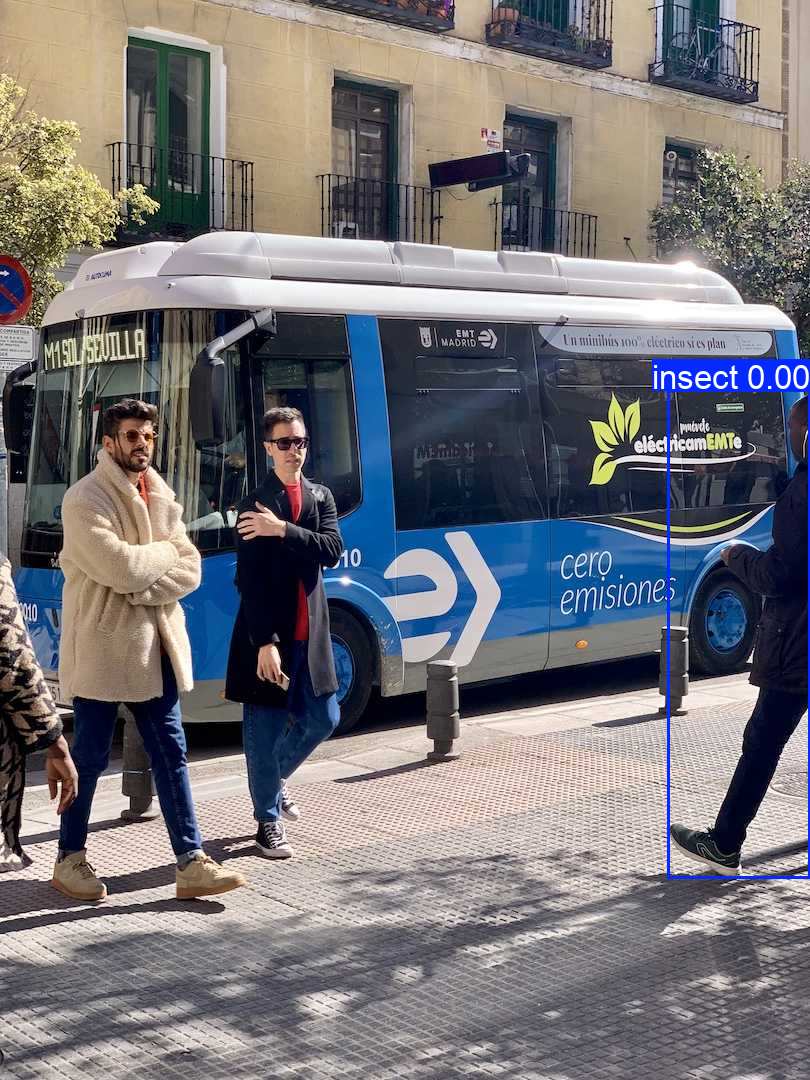

In [7]:
# Load the deployed YOLOv8s-worldv2 model
model = YOLOWorld("models/yolov8s-worldv2.pt")
# Set custom open-vocabulary classes before inference
model.set_classes(classes)
# Run inference
results = model("data/smoke_images/bus.jpg", conf=confidence_threshold, iou=overlap_threshold, imgsz=image_size)
results[0].plot(pil=True)

## Insects caught in this smoke test

Count a labeled insect as **caught if its ground-truth box overlaps any prediction shown in the insect grid**. Partial overlap counts. Each labeled insect is counted once, and one prediction can cover several insects. Ignore prediction boxes covering **90% or more of the image**; that limit is adjustable below.

In [8]:
from pathlib import Path

# Reject almost-full-image boxes. 0.90 means 90% of the photo's area.
maximum_image_area_fraction = 0.90

# Use the exact boxes already displayed in the insect smoke-test grid.
if "smoke_predictions" not in globals() or set(smoke_predictions) != set(range(1, 11)):
    raise RuntimeError("Run the Insect Smoke Test grid cell first.")

total_caught = 0
total_labeled = 0
total_ignored_boxes = 0

print(f"{'Image':<12} {'Caught':>6} {'Labeled':>8} {'Missed':>7}")

for image_number in range(1, 11):
    prediction = smoke_predictions[image_number]
    image_height, image_width = prediction.orig_shape
    image_area = image_width * image_height

    # These coordinates are in the original image's pixels.
    usable_boxes = []
    for box in prediction.boxes.xyxy.cpu().tolist():
        left, top, right, bottom = box
        box_area = (right - left) * (bottom - top)
        if box_area < maximum_image_area_fraction * image_area:
            usable_boxes.append(box)
        else:
            total_ignored_boxes += 1

    label_path = Path(f"data/insect_samples/img{image_number}.txt")
    label_rows = [line for line in label_path.read_text().splitlines() if line.strip()]
    caught = 0

    for row in label_rows:
        _, center_x, center_y, width, height = map(float, row.split())

        # Convert the labeled insect box from image fractions to pixels.
        truth_left = (center_x - width / 2) * image_width
        truth_top = (center_y - height / 2) * image_height
        truth_right = (center_x + width / 2) * image_width
        truth_bottom = (center_y + height / 2) * image_height

        for left, top, right, bottom in usable_boxes:
            overlap_width = min(right, truth_right) - max(left, truth_left)
            overlap_height = min(bottom, truth_bottom) - max(top, truth_top)

            # Any shared area counts; no tight-box or extra score requirement.
            if overlap_width > 0 and overlap_height > 0:
                caught += 1
                break  # Count this insect once, even if several boxes cover it.

    labeled = len(label_rows)
    total_caught += caught
    total_labeled += labeled
    print(f"{f'img{image_number}.jpg':<12} {caught:>6} {labeled:>8} {labeled - caught:>7}")

print(f"\nTotal caught: {total_caught}/{total_labeled} insects ({total_caught / total_labeled:.1%})")
print(f"Ignored {total_ignored_boxes} boxes covering at least {maximum_image_area_fraction:.0%} of an image.")


Image        Caught  Labeled  Missed
img1.jpg          1        1       0
img2.jpg          0        2       2
img3.jpg          0        1       1
img4.jpg          1        4       3
img5.jpg          0        1       1
img6.jpg          0        1       1
img7.jpg          1        1       0
img8.jpg          1        1       0
img9.jpg          2        3       1
img10.jpg         0        1       1

Total caught: 6/16 insects (37.5%)
Ignored 1 boxes covering at least 90% of an image.
